In [9]:

from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from rest_of_season.config import (
    SEASON,
    CURRENT_WEEK,
    CURRENT_OUTPUT_DIR
)

TARGET_WEEK = CURRENT_WEEK
ROS_OUTPUT_DIR = CURRENT_OUTPUT_DIR

standings = pd.read_csv(
    ROS_OUTPUT_DIR / "final_division_standings.csv"
)

finish_probabilities = pd.read_csv(
    ROS_OUTPUT_DIR / "division_finish_probabilities.csv"
)

assert len(standings) == 32
assert standings["team"].nunique() == 32
assert standings["division"].nunique() == 8

assert standings[
    [
        "expected_wins",
        "expected_losses",
        "expected_ties",
        "first_place",
        "second_place",
        "third_place",
        "fourth_place"
    ]
].notna().all().all()

print("Dashboard data loaded successfully.")
print("Season:", SEASON)
print("Projection week:", TARGET_WEEK)
print(f"Teams: {standings['team'].nunique()}")
print(f"Divisions: {standings['division'].nunique()}")
print(f"Output directory: {ROS_OUTPUT_DIR}")

display(standings.head(8))


Dashboard data loaded successfully.
Season: 2026
Projection week: 8
Teams: 32
Divisions: 8
Output directory: C:\Users\efriedman\Desktop\NFL-Season-Projections\rest_of_season\outputs\week_08


,division,team,expected_wins,expected_losses,expected_ties,most_likely_record,first_place,second_place,third_place,fourth_place
0,AFC East,BUF,11.98202,5.01798,0.0,12-5-0,0.76908,0.22334,0.00716,0.00042
1,AFC East,NE,9.77980,7.22020,0.0,10-7-0,0.22838,0.73148,0.03542,0.00472
2,AFC East,NYJ,5.60244,11.39756,0.0,5-12-0,0.00172,0.02316,0.56120,0.41392
3,AFC East,MIA,4.65138,12.34862,0.0,4-13-0,0.00082,0.02202,0.39622,0.58094
4,AFC North,CIN,10.70148,6.29852,0.0,11-6-0,0.39648,0.30916,0.18458,0.10974
5,AFC North,PIT,10.54266,6.45734,0.0,11-6-0,0.36946,0.30206,0.20068,0.12776
6,AFC North,CLE,9.19856,7.80144,0.0,9-8-0,0.13910,0.21192,0.32260,0.32634
7,AFC North,BAL,9.13500,7.86500,0.0,9-8-0,0.09494,0.17682,0.29210,0.43612


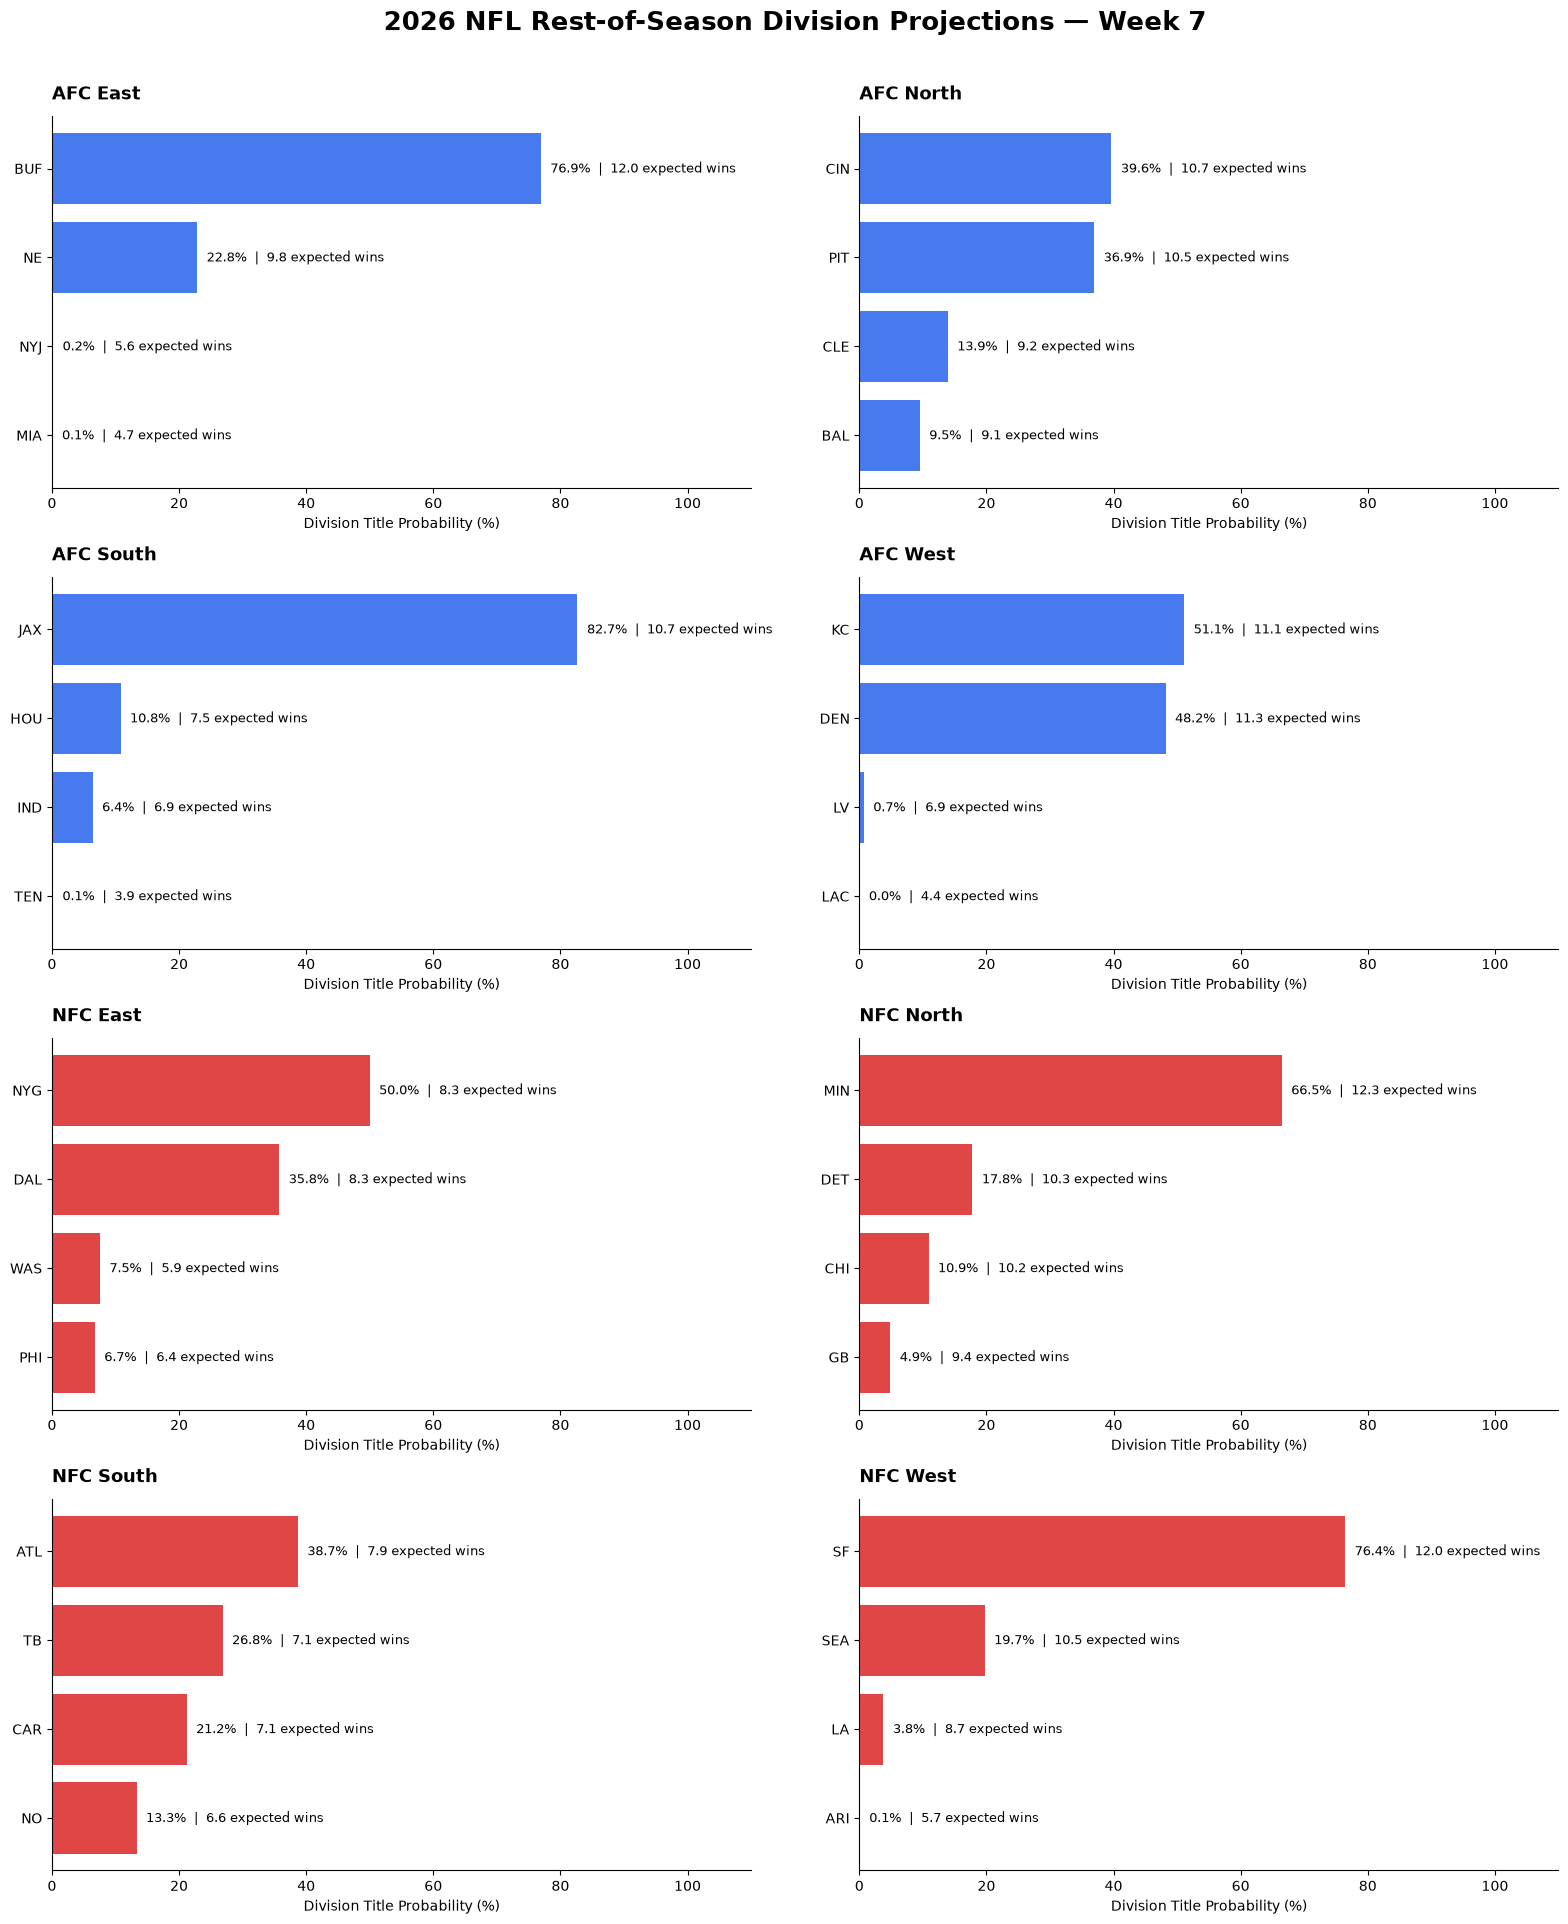

In [10]:
import matplotlib.pyplot as plt

# Division order
division_order = [
    "AFC East", "AFC North", "AFC South", "AFC West",
    "NFC East", "NFC North", "NFC South", "NFC West"
]

fig, axes = plt.subplots(
    4, 2,
    figsize=(16, 19)
)

axes = axes.flatten()

for i, division in enumerate(division_order):

    ax = axes[i]

    # Get teams in the division
    division_data = standings[
        standings["division"] == division
    ].sort_values(
        "first_place",
        ascending=False
    )

    teams = division_data["team"].tolist()
    probabilities = division_data["first_place"].to_numpy()

    # Horizontal bars
    bars = ax.barh(
        teams,
        probabilities * 100,
        color="#2563EB" if division.startswith("AFC") else "#DC2626",
        alpha=0.85
    )

    ax.invert_yaxis()
    ax.set_xlim(0, 110)

    # Add division title probabilities and expected records
    for bar, (_, row) in zip(bars, division_data.iterrows()):

        width = bar.get_width()
        y = bar.get_y() + bar.get_height() / 2

        ax.text(
            width + 1.5,
            y,
            f"{row['first_place']:.1%}  |  "
            f"{row['expected_wins']:.1f} expected wins",
            va="center",
            fontsize=9
        )

    ax.set_title(
        division,
        fontsize=13,
        fontweight="bold",
        loc="left",
        pad=12
    )

    ax.set_xlabel("Division Title Probability (%)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "2026 NFL Rest-of-Season Division Projections — Week 7",
    fontsize=19,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

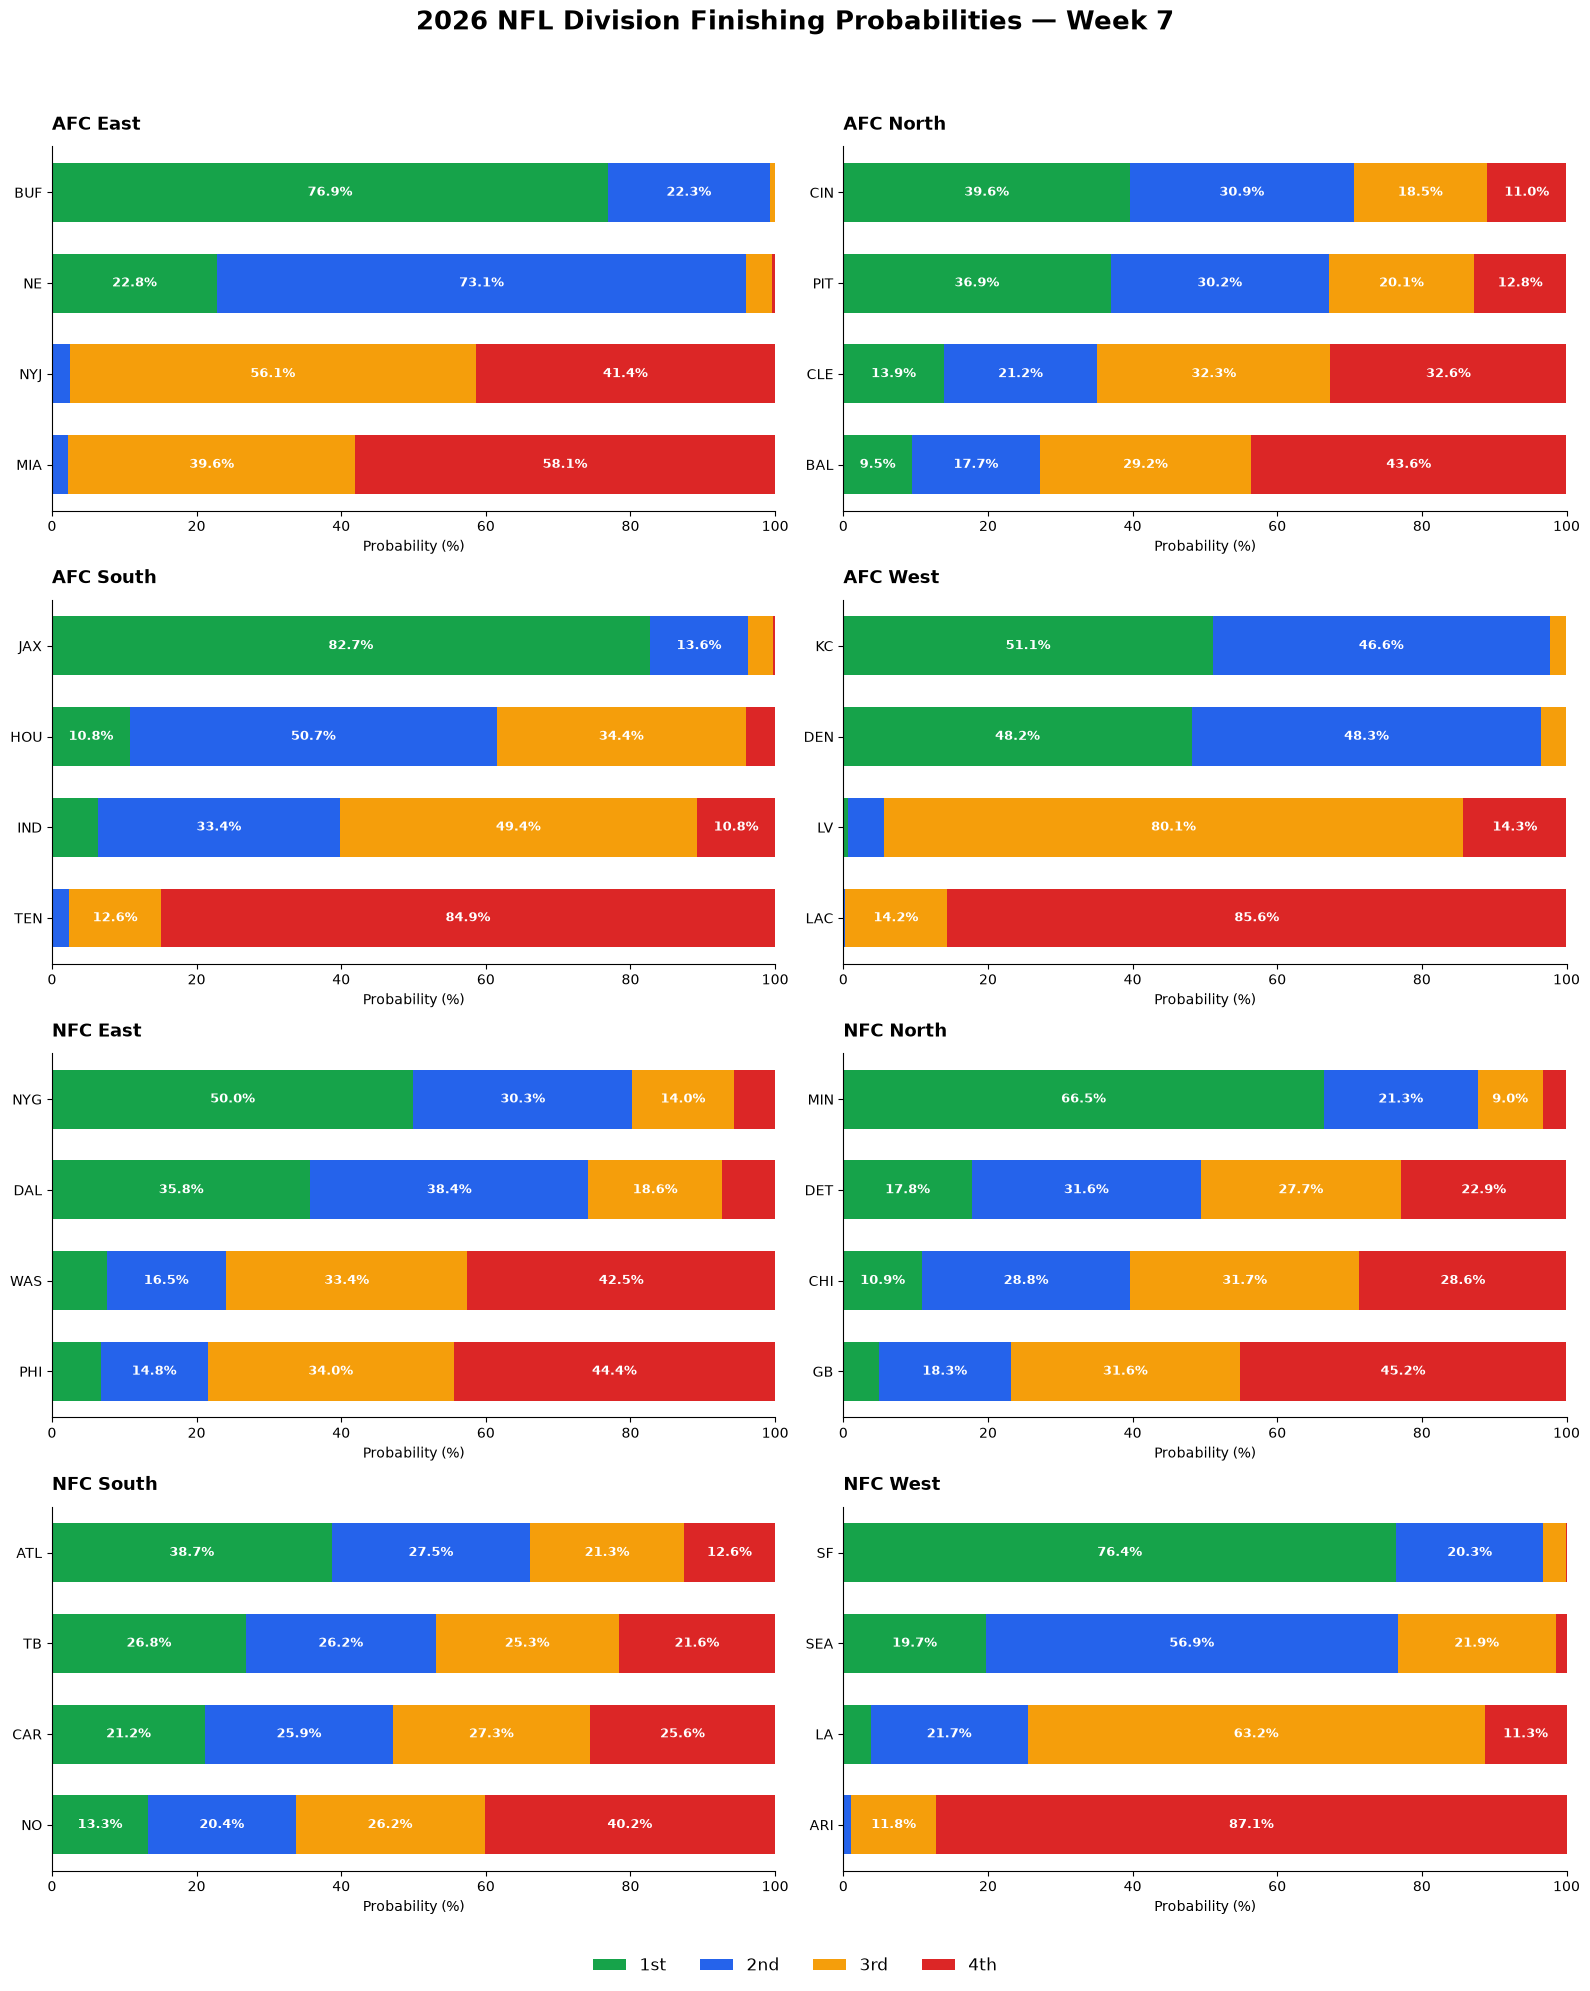

In [11]:
import matplotlib.pyplot as plt
import numpy as np

positions = [
    "first_place",
    "second_place",
    "third_place",
    "fourth_place"
]

position_labels = ["1st", "2nd", "3rd", "4th"]

position_colors = [
    "#16A34A",  # 1st - green
    "#2563EB",  # 2nd - blue
    "#F59E0B",  # 3rd - amber
    "#DC2626"   # 4th - red
]

fig, axes = plt.subplots(
    4, 2,
    figsize=(16, 20)
)

axes = axes.flatten()

for i, division in enumerate(division_order):

    ax = axes[i]

    division_data = standings[
        standings["division"] == division
    ].sort_values(
        "first_place",
        ascending=False
    )

    teams = division_data["team"].tolist()
    y_positions = np.arange(len(teams))

    left = np.zeros(len(teams))

    for position, label, color in zip(
        positions,
        position_labels,
        position_colors
    ):

        probabilities = (
            division_data[position].to_numpy() * 100
        )

        bars = ax.barh(
            y_positions,
            probabilities,
            left=left,
            color=color,
            label=label,
            height=0.65
        )

        # Label segments large enough to display clearly
        for bar, probability in zip(bars, probabilities):

            if probability >= 8:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_y() + bar.get_height() / 2,
                    f"{probability:.1f}%",
                    ha="center",
                    va="center",
                    fontsize=9,
                    color="white",
                    fontweight="bold"
                )

        left += probabilities

    ax.set_yticks(y_positions)
    ax.set_yticklabels(teams)
    ax.invert_yaxis()

    ax.set_xlim(0, 100)
    ax.set_xlabel("Probability (%)")

    ax.set_title(
        division,
        fontsize=13,
        fontweight="bold",
        loc="left",
        pad=12
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "2026 NFL Division Finishing Probabilities — Week 7",
    fontsize=19,
    fontweight="bold",
    y=0.995
)

fig.legend(
    position_labels,
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, 0.005),
    frameon=False,
    fontsize=12
)

plt.tight_layout(rect=[0, 0.035, 1, 0.97])
plt.show()

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

competitiveness_results = []

for division in division_order:

    division_data = standings[
        standings["division"] == division
    ]

    probabilities = division_data["first_place"].to_numpy()

    # Normalize to account for the very small number
    # of unresolved division-title outcomes
    probabilities = probabilities / probabilities.sum()

    # Shannon entropy, normalized to a 0-1 scale
    entropy = -np.sum(
        probabilities[probabilities > 0]
        * np.log2(probabilities[probabilities > 0])
    )

    normalized_entropy = entropy / np.log2(4)

    # Additional competitiveness metrics
    sorted_probs = np.sort(probabilities)[::-1]

    competitiveness_results.append({
        "division": division,
        "competitiveness_score": normalized_entropy,
        "favorite": division_data.loc[
            division_data["first_place"].idxmax(), "team"
        ],
        "favorite_probability": sorted_probs[0],
        "top_two_gap": sorted_probs[0] - sorted_probs[1]
    })

division_competitiveness = pd.DataFrame(
    competitiveness_results
).sort_values(
    "competitiveness_score",
    ascending=False
).reset_index(drop=True)

print("Division Competitiveness Rankings\n")

print(
    division_competitiveness.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

Division Competitiveness Rankings

 division  competitiveness_score favorite  favorite_probability  top_two_gap
NFC South                 0.9504      ATL                0.3867       0.1184
AFC North                 0.8891      CIN                0.3965       0.0270
 NFC East                 0.7871      NYG                0.4997       0.1422
NFC North                 0.6977      MIN                0.6646       0.4866
 AFC West                 0.5268       KC                0.5111       0.0292
 NFC West                 0.4714       SF                0.7644       0.5672
AFC South                 0.4203      JAX                0.8268       0.7189
 AFC East                 0.4010      BUF                0.7691       0.5407


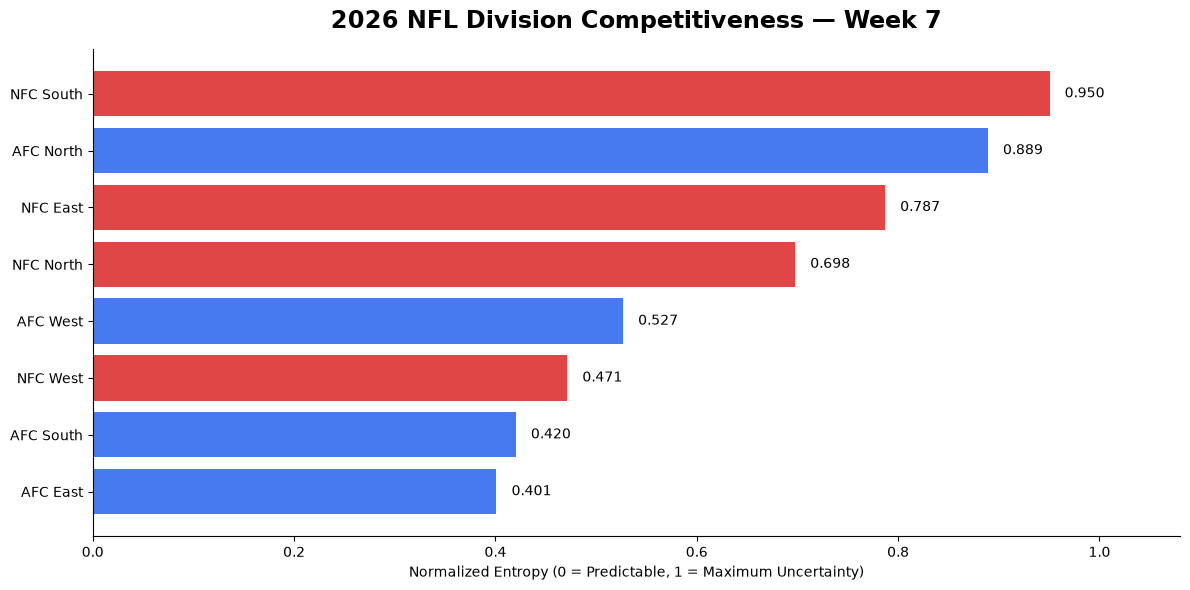

In [13]:
fig, ax = plt.subplots(figsize=(12, 6))

colors = [
    "#DC2626" if division.startswith("NFC") else "#2563EB"
    for division in division_competitiveness["division"]
]

bars = ax.barh(
    division_competitiveness["division"],
    division_competitiveness["competitiveness_score"],
    color=colors,
    alpha=0.85
)

ax.invert_yaxis()
ax.set_xlim(0, 1.08)

for bar in bars:
    ax.text(
        bar.get_width() + 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.3f}",
        va="center",
        fontsize=10
    )

ax.set_title(
    "2026 NFL Division Competitiveness — Week 7",
    fontsize=17,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Normalized Entropy (0 = Predictable, 1 = Maximum Uncertainty)"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

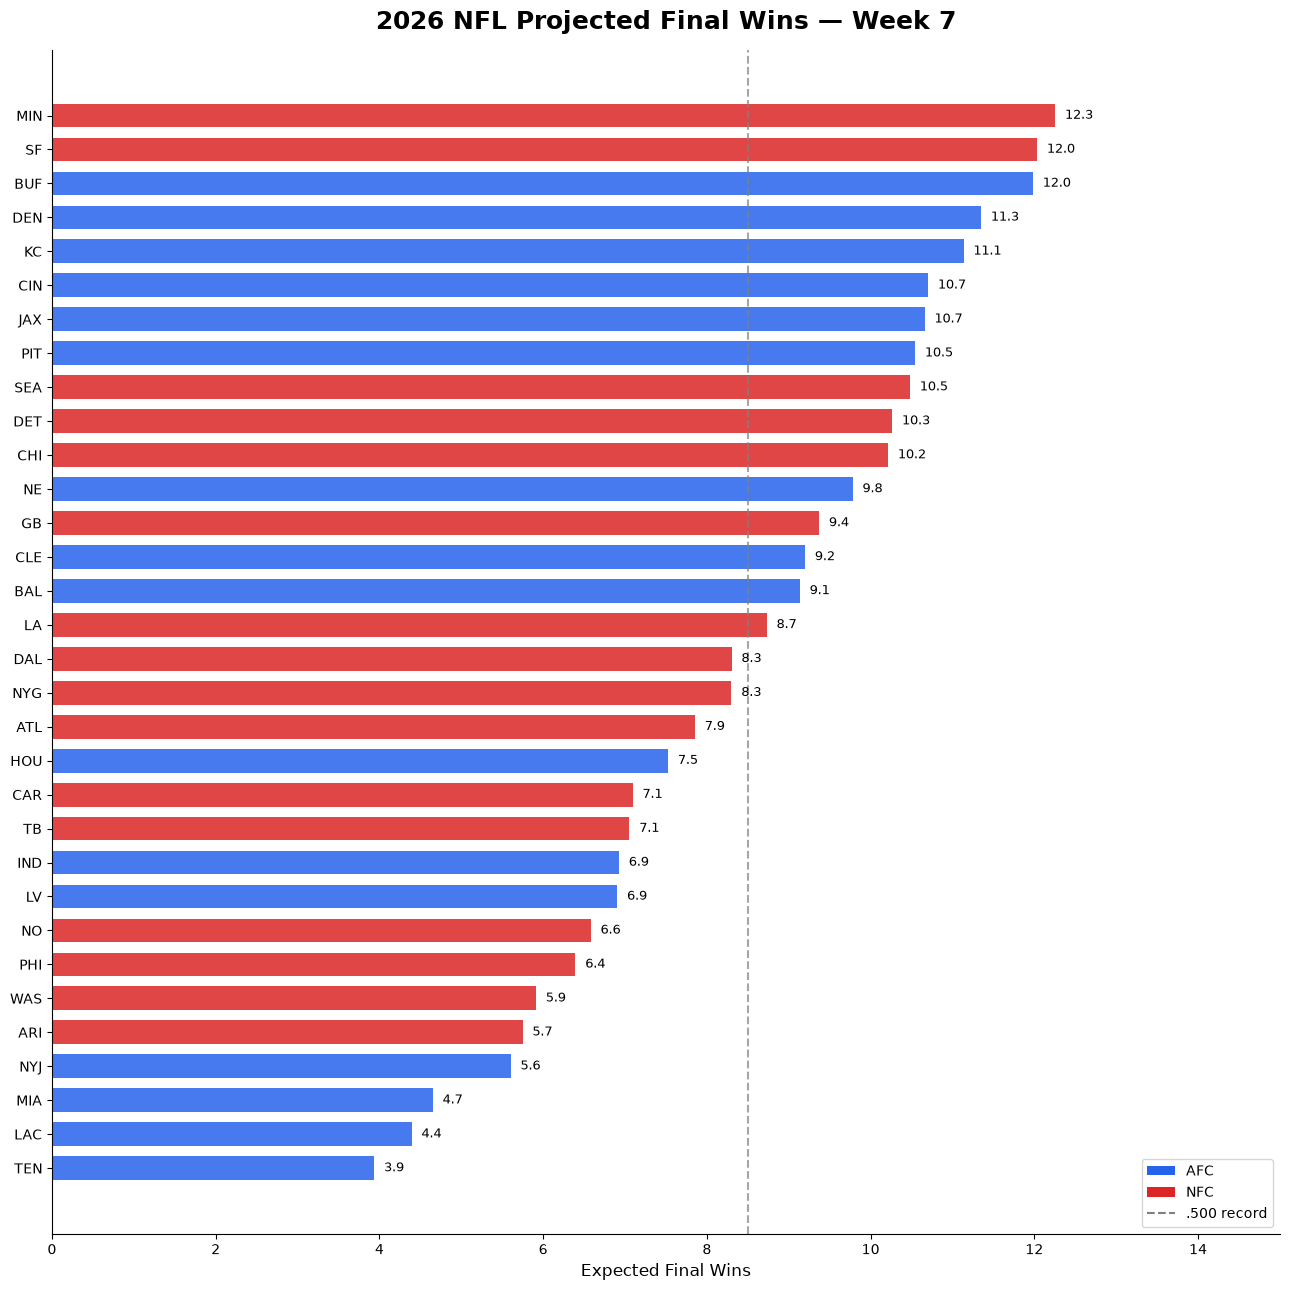

In [14]:
# Sort all 32 teams by expected wins
league_projections = standings.sort_values(
    "expected_wins",
    ascending=True
).copy()

# Separate AFC and NFC teams
colors = [
    "#2563EB" if division.startswith("AFC") else "#DC2626"
    for division in league_projections["division"]
]

fig, ax = plt.subplots(figsize=(13, 13))

bars = ax.barh(
    league_projections["team"],
    league_projections["expected_wins"],
    color=colors,
    alpha=0.85,
    height=0.7
)

# Add expected wins to the end of each bar
for bar in bars:
    ax.text(
        bar.get_width() + 0.12,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}",
        va="center",
        fontsize=9
    )

# Reference line for a .500 record
ax.axvline(
    8.5,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    alpha=0.7,
    label=".500 record (8.5 wins)"
)

ax.set_xlim(0, 15)

ax.set_title(
    "2026 NFL Projected Final Wins — Week 7",
    fontsize=18,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Expected Final Wins", fontsize=12)
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(facecolor="#2563EB", label="AFC"),
        Patch(facecolor="#DC2626", label="NFC"),
        plt.Line2D(
            [0], [0],
            color="gray",
            linestyle="--",
            label=".500 record"
        )
    ],
    loc="lower right"
)

plt.tight_layout()
plt.show()

In [15]:
from pathlib import Path
import matplotlib.pyplot as plt

DASHBOARD_DIR = ROS_OUTPUT_DIR / "dashboard"
DASHBOARD_DIR.mkdir(parents=True, exist_ok=True)

# Save the currently active figure (projected wins)
fig.savefig(
    DASHBOARD_DIR / "projected_final_wins.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved projected_final_wins.png")

Saved projected_final_wins.png


In [16]:
from pathlib import Path
from IPython.display import display

DASHBOARD_DIR = ROS_OUTPUT_DIR / "dashboard"
DASHBOARD_DIR.mkdir(parents=True, exist_ok=True)

chart_names = [
    "division_title_probabilities.png",
    "division_finish_probabilities.png",
    "division_competitiveness.png",
    "projected_final_wins.png"
]

# Jupyter may close figures after plt.show().
# Reuse the charts already displayed by earlier cells
# rather than relying on plt.get_fignums().

from IPython import get_ipython

outputs = get_ipython().user_ns.get("Out", {})

print("Dashboard directory:", DASHBOARD_DIR)
print("Expected charts:", len(chart_names))
print(
    "Matplotlib figures still open:",
    len(plt.get_fignums())
)

Dashboard directory: C:\Users\efriedman\Desktop\NFL-Season-Projections\rest_of_season\outputs\week_08\dashboard
Expected charts: 4
Matplotlib figures still open: 0


In [17]:
# Validate the final dashboard dataset

assert len(standings) == 32
assert standings["team"].nunique() == 32
assert standings["division"].nunique() == 8

# Every team must have a 17-game final record
assert np.allclose(
    standings["expected_wins"]
    + standings["expected_losses"]
    + standings["expected_ties"],
    17
)

# Probabilities must remain between 0 and 1
probability_columns = [
    "first_place",
    "second_place",
    "third_place",
    "fourth_place"
]

assert standings[probability_columns].ge(0).all().all()
assert standings[probability_columns].le(1).all().all()

# Small deficits are expected from unresolved tiebreakers
assert np.allclose(
    standings[probability_columns].sum(axis=1),
    1,
    atol=0.0002
)

# Save competitiveness metrics
division_competitiveness.to_csv(
    ROS_OUTPUT_DIR / "division_competitiveness.csv",
    index=False
)

print("All dashboard validations passed.")
print("Dashboard outputs:", DASHBOARD_DIR)

All dashboard validations passed.
Dashboard outputs: C:\Users\efriedman\Desktop\NFL-Season-Projections\rest_of_season\outputs\week_08\dashboard
